# Star Classification Using Machine Learning
Goal: classify an observation as STAR, GALAXY, or QSO.



In [4]:
import os, json, time, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (8, 5)

In [5]:
%pip install scikit-learn==1.9.0


Note: you may need to restart the kernel to use updated packages.


In [6]:
import sklearn
print(sklearn.__version__)

1.9.0


## 1. Load and inspect the dataset

In [7]:
df = pd.read_csv("star_classification.csv")
print("Shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nSummary:")
display(df.describe().T)
df.info()

Shape: (100000, 18)


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842



Columns: ['obj_ID', 'alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'run_ID', 'rerun_ID', 'cam_col', 'field_ID', 'spec_obj_ID', 'class', 'redshift', 'plate', 'MJD', 'fiber_ID']

Data types:
obj_ID         float64
alpha          float64
delta          float64
u              float64
g              float64
r              float64
i              float64
z              float64
run_ID           int64
rerun_ID         int64
cam_col          int64
field_ID         int64
spec_obj_ID    float64
class           object
redshift       float64
plate            int64
MJD              int64
fiber_ID         int64
dtype: object

Summary:


,count,mean,std,min,25%,50%,75%,max
obj_ID,100000.0,1.237665e+18,8.438560e+12,1.237646e+18,1.237659e+18,1.237663e+18,1.237668e+18,1.237681e+18
alpha,100000.0,1.776291e+02,9.650224e+01,5.527828e-03,1.275182e+02,1.809007e+02,2.338950e+02,3.599998e+02
delta,100000.0,2.413530e+01,1.964467e+01,-1.878533e+01,5.146771e+00,2.364592e+01,3.990155e+01,8.300052e+01
u,100000.0,2.198047e+01,3.176929e+01,-9.999000e+03,2.035235e+01,2.217914e+01,2.368744e+01,3.278139e+01
g,100000.0,2.053139e+01,3.175029e+01,-9.999000e+03,1.896523e+01,2.109983e+01,2.212377e+01,3.160224e+01
r,100000.0,1.964576e+01,1.854760e+00,9.822070e+00,1.813583e+01,2.012529e+01,2.104478e+01,2.957186e+01
i,100000.0,1.908485e+01,1.757895e+00,9.469903e+00,1.773228e+01,1.940514e+01,2.039650e+01,3.214147e+01
z,100000.0,1.866881e+01,3.172815e+01,-9.999000e+03,1.746068e+01,1.900460e+01,1.992112e+01,2.938374e+01
run_ID,100000.0,4.481366e+03,1.964765e+03,1.090000e+02,3.187000e+03,4.188000e+03,5.326000e+03,8.162000e+03
rerun_ID,100000.0,3.010000e+02,0.000000e+00,3.010000e+02,3.010000e+02,3.010000e+02,3.010000e+02,3.010000e+02


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  float64
 13  class        100000 non-null  object 
 14  redshift     100000 non-null  float64
 15  plate        100000 non-null  int64  
 16  MJD          100000 non-null  int64  
 17  fiber_ID     100000 non-null  int64  
dtypes: float64(10), int64(7),

## 2. Missing values and duplicates

Duplicate rows: 0


,Missing,Missing %


No missing values found in this dataset.


IndexError: index 0 is out of bounds for axis 0 with size 0

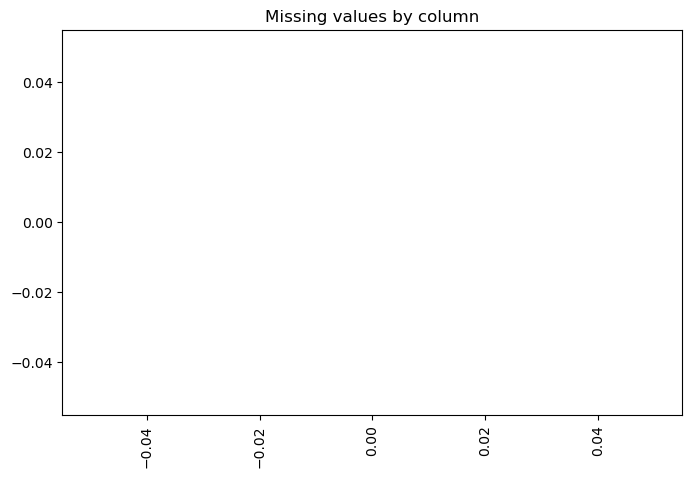

In [8]:
print("Duplicate rows:", df.duplicated().sum())
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
display(pd.DataFrame({"Missing": missing, "Missing %": missing_pct})[missing > 0])
if missing.sum() == 0:
    print("No missing values found in this dataset.")
missing[missing > 0].plot(kind="bar", title="Missing values by column")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 3. Target class distribution

class
GALAXY    59445
STAR      21594
QSO       18961
Name: count, dtype: int64
class
GALAXY    59.44
STAR      21.59
QSO       18.96
Name: proportion, dtype: float64


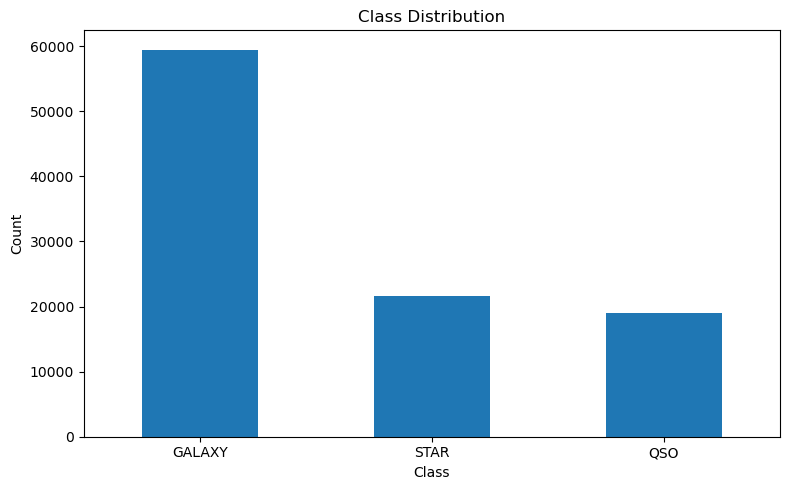

In [9]:
if "class" not in df.columns:
    raise ValueError("Target column 'class' was not found.")
print(df["class"].value_counts())
print((df["class"].value_counts(normalize=True) * 100).round(2))
df["class"].value_counts().plot(kind="bar")
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Select features and target

In [10]:
FEATURES = ["u", "g", "r", "i", "z"]
TARGET = "class"
missing_columns = [c for c in FEATURES + [TARGET] if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

# IDs and survey metadata are excluded from the first model.
data = df[FEATURES + [TARGET]].copy()
data = data.dropna(subset=[TARGET])
for col in FEATURES:
    data[col] = pd.to_numeric(data[col], errors="coerce")
X = data[FEATURES]
y = data[TARGET].astype(str).str.strip().str.upper()
print("Features:", FEATURES)
print("Classes:", sorted(y.unique()))
print("Rows for modelling:", len(data))
display(X.head())

Features: ['u', 'g', 'r', 'i', 'z']
Classes: ['GALAXY', 'QSO', 'STAR']
Rows for modelling: 100000


,u,g,r,i,z
0,23.87882,22.27530,20.39501,19.16573,18.79371
1,24.77759,22.83188,22.58444,21.16812,21.61427
2,25.26307,22.66389,20.60976,19.34857,18.94827
3,22.13682,23.77656,21.61162,20.50454,19.25010
4,19.43718,17.58028,16.49747,15.97711,15.54461


## 5. Feature distributions

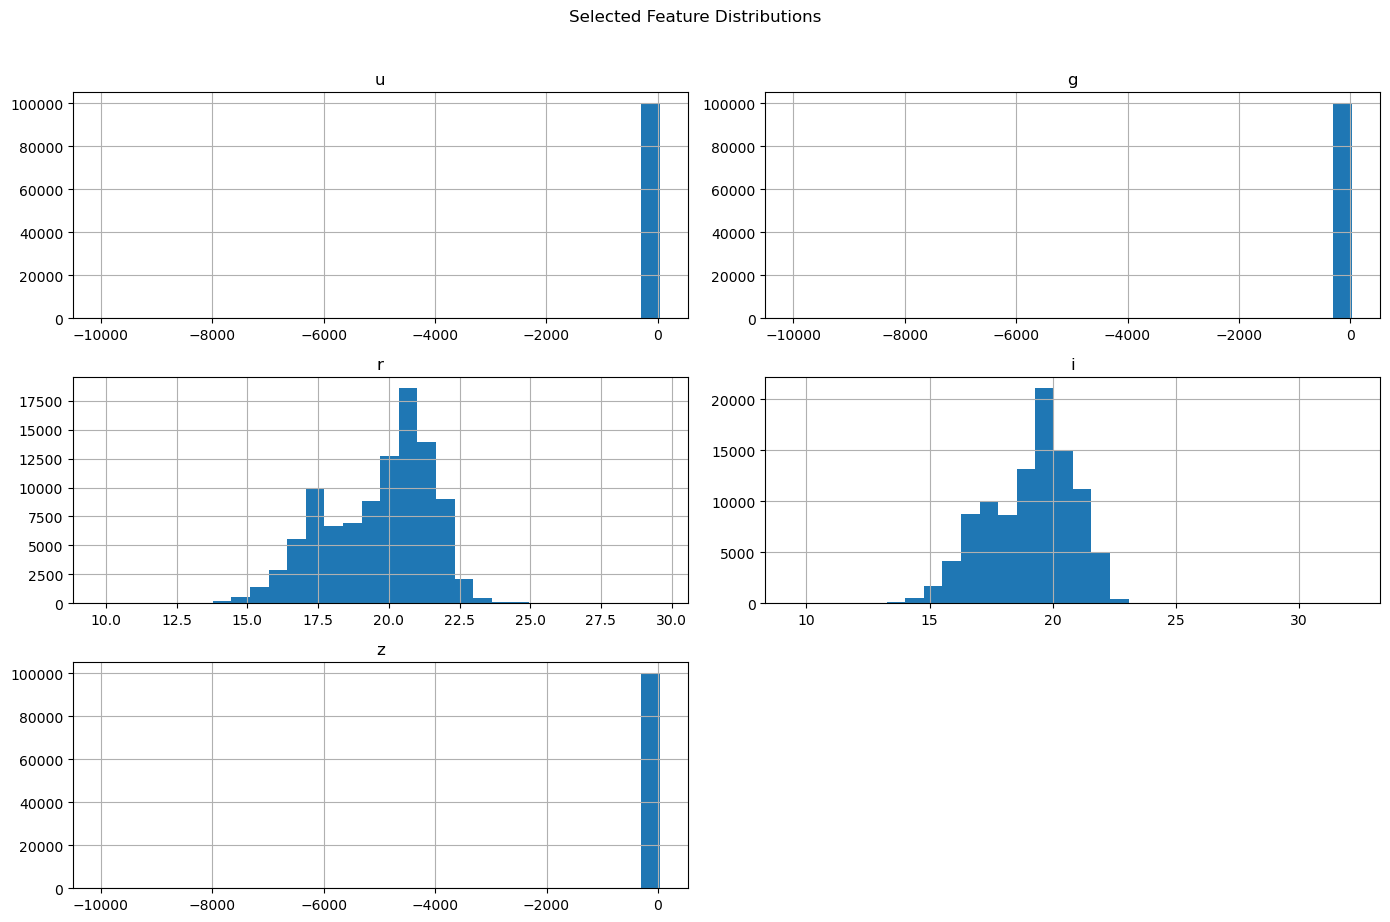

In [11]:
X.hist(bins=30, figsize=(14, 9))
plt.suptitle("Selected Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

## 6. Outlier analysis

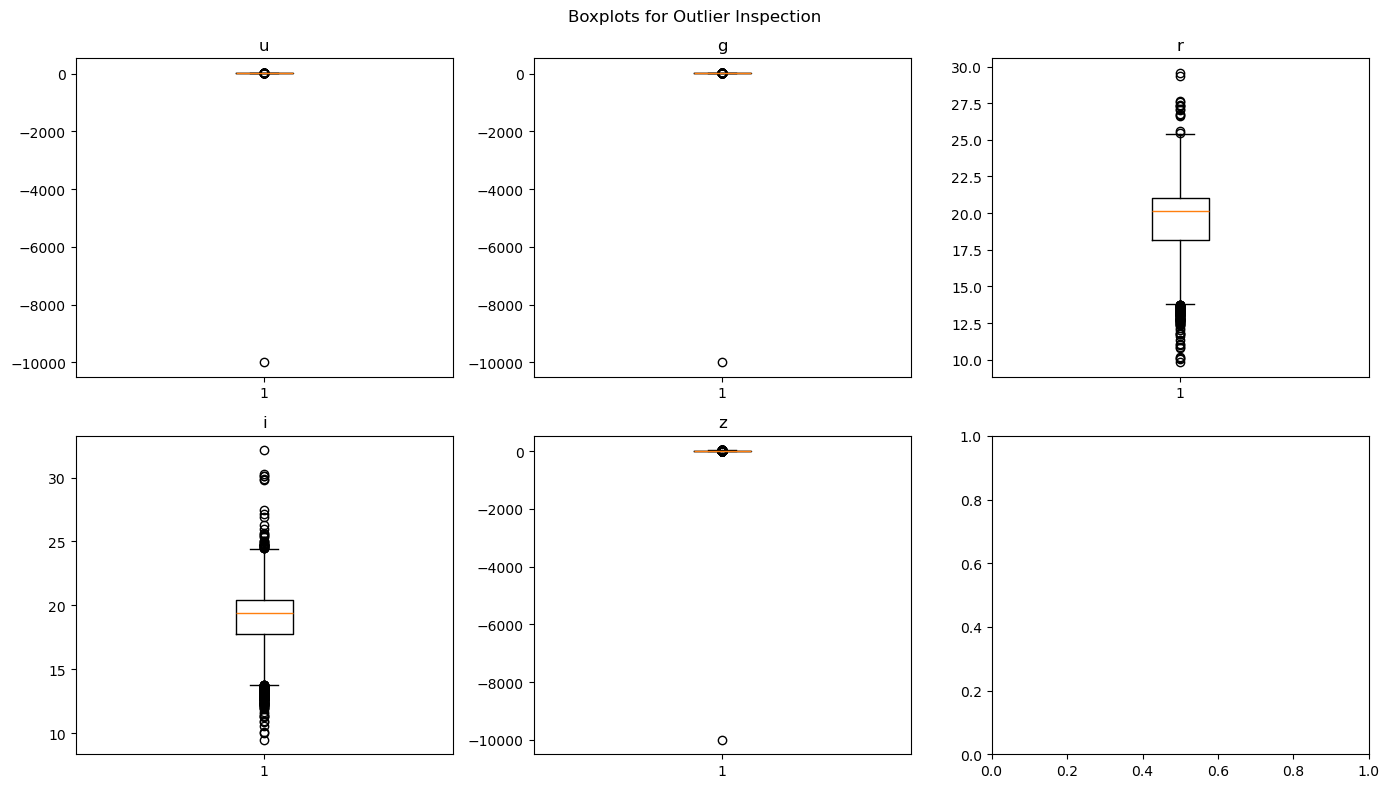

,Feature,Q1,Q3,IQR,Outlier count,Outlier %
0,u,20.352353,23.687440,3.335088,56,0.06
1,g,18.965230,22.123767,3.158538,99,0.10
2,r,18.135828,21.044785,2.908957,132,0.13
3,i,17.732285,20.396495,2.664210,198,0.20
4,z,17.460677,19.921120,2.460442,320,0.32


Outliers are inspected, not automatically removed; extreme astronomy values may be meaningful.


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for col, ax in zip(FEATURES, axes.flatten()):
    ax.boxplot(X[col].dropna(), showfliers=True)
    ax.set_title(col)
plt.suptitle("Boxplots for Outlier Inspection")
plt.tight_layout()
plt.show()

rows = []
for col in FEATURES:
    values = X[col].dropna()
    q1, q3 = values.quantile(.25), values.quantile(.75)
    iqr = q3 - q1
    count = ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum()
    rows.append([col, q1, q3, iqr, count, round(count / max(len(values), 1) * 100, 2)])
display(pd.DataFrame(rows, columns=["Feature", "Q1", "Q3", "IQR", "Outlier count", "Outlier %"]))
print("Outliers are inspected, not automatically removed; extreme astronomy values may be meaningful.")

## 7. Correlation heatmap

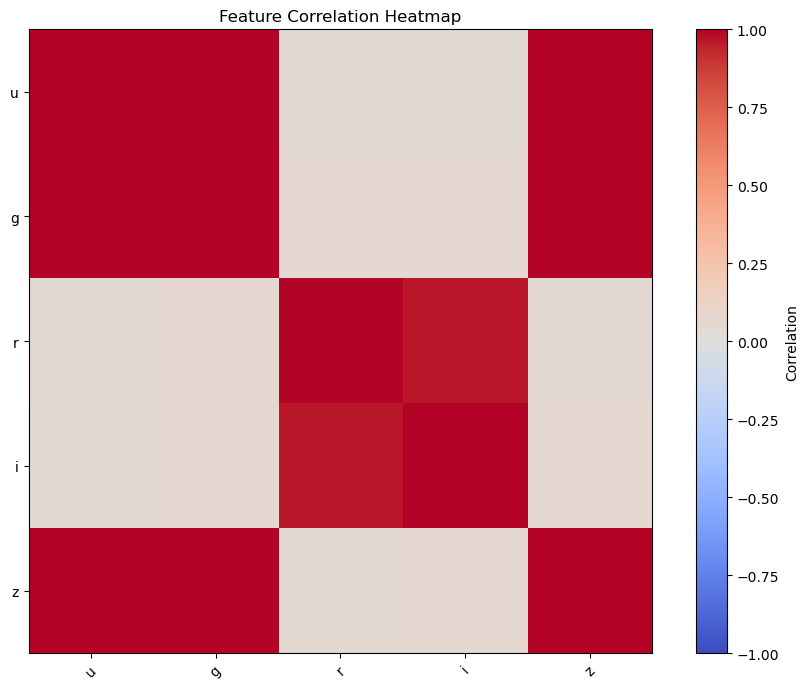

In [13]:
corr = X.corr(numeric_only=True)
plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

## 8. Feature values by class

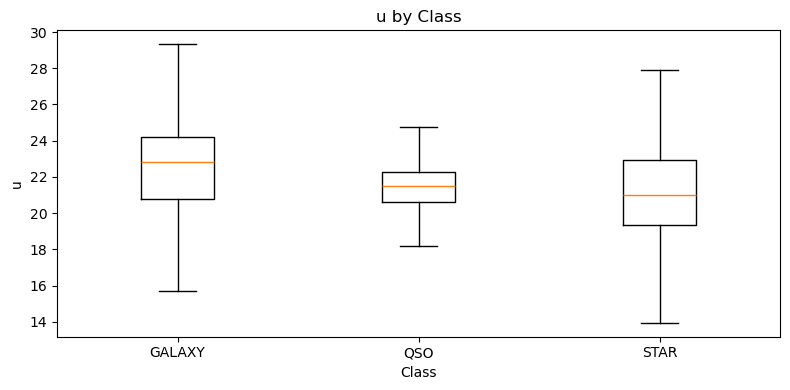

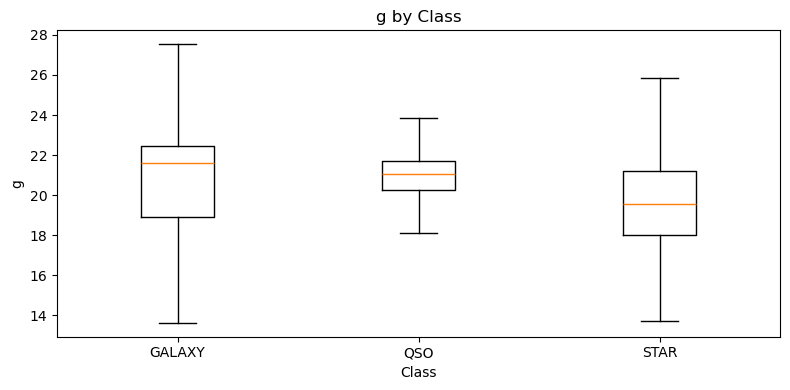

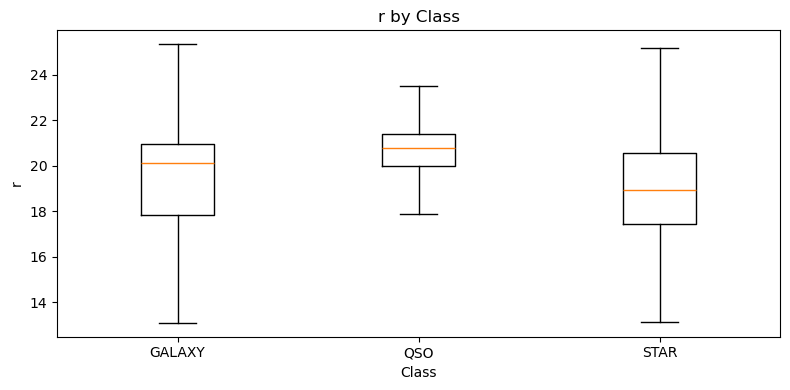

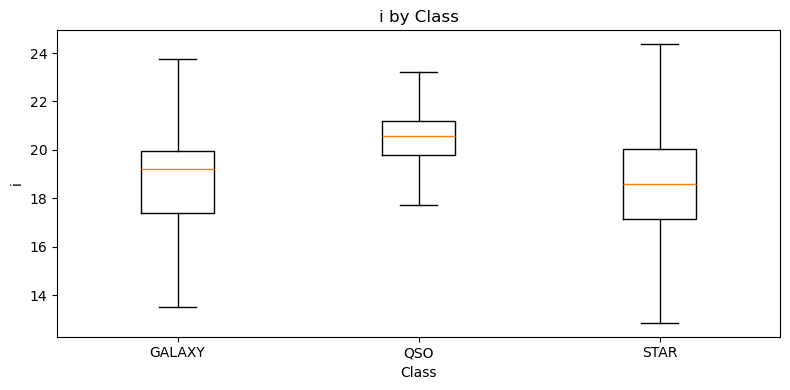

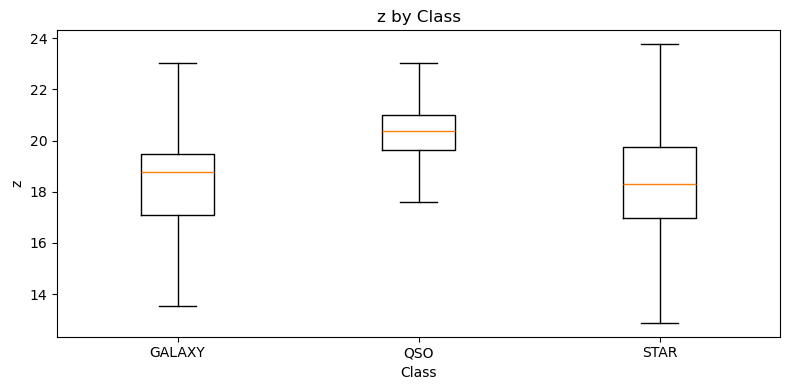

In [14]:
for col in FEATURES:
    labels = sorted(y.unique())
    values = [X.loc[y == label, col].dropna().values for label in labels]
    plt.figure(figsize=(8, 4))
    plt.boxplot(values, labels=labels, showfliers=False)
    plt.title(f"{col} by Class")
    plt.xlabel("Class")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

## 9. Train-test split and preprocessing

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Train class proportions:")
print(y_train.value_counts(normalize=True).round(3))

# Median imputation is fitted on training data only. Scaling is useful for SVM.
# Keeping preprocessing in each pipeline prevents data leakage.

Training rows: 80000
Testing rows: 20000
Train class proportions:
class
GALAXY    0.594
STAR      0.216
QSO       0.190
Name: proportion, dtype: float64


## 10. Evaluation helper

In [16]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE,
                                            n_jobs=-1, class_weight="balanced_subsample"),
    "SVM": SVC(kernel="rbf", C=3, class_weight="balanced"),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1,
                                                         random_state=RANDOM_STATE)
}
results, trained_models, predictions = [], {}, {}

def evaluate_model(name):
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", models[name])
    ])
    start = time.time()
    pipeline.fit(X_train, y_train)
    seconds = time.time() - start
    pred = pipeline.predict(X_test)
    trained_models[name] = pipeline
    predictions[name] = pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro Precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_test, pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_test, pred, average="weighted", zero_division=0),
        "Training Time (seconds)": seconds
    })
    print(classification_report(y_test, pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=sorted(y.unique()), xticks_rotation=45,
        cmap="Blues", values_format="d"
    )
    plt.title(f"{name} — Confusion Matrix")
    plt.tight_layout()
    plt.show()
    return pipeline

## 11. Model 1 — Decision Tree

              precision    recall  f1-score   support

      GALAXY       0.88      0.88      0.88     11889
         QSO       0.72      0.72      0.72      3792
        STAR       0.71      0.71      0.71      4319

    accuracy                           0.81     20000
   macro avg       0.77      0.77      0.77     20000
weighted avg       0.81      0.81      0.81     20000



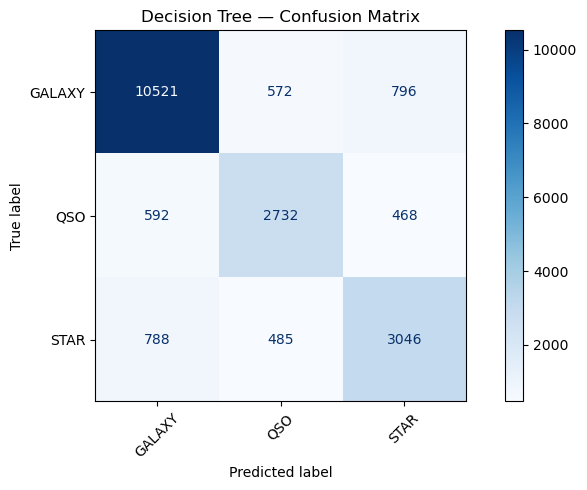

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['GALAXY','QSO','STAR']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['u','g','r','i','z']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be

In [17]:
evaluate_model("Decision Tree")

## 12. Model 2 — Random Forest

              precision    recall  f1-score   support

      GALAXY       0.91      0.95      0.93     11889
         QSO       0.81      0.80      0.81      3792
        STAR       0.83      0.75      0.79      4319

    accuracy                           0.88     20000
   macro avg       0.85      0.83      0.84     20000
weighted avg       0.87      0.88      0.87     20000



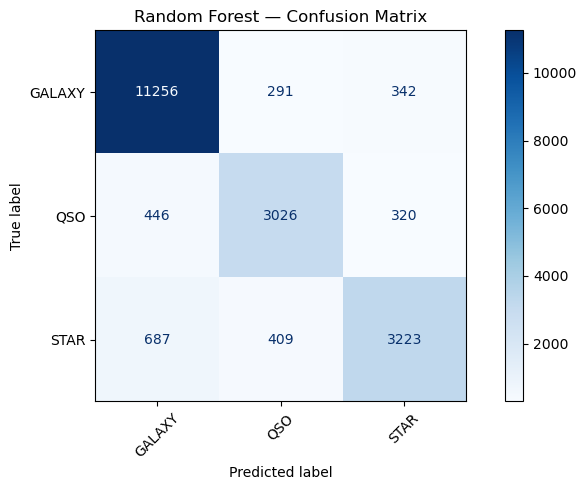

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['GALAXY','QSO','STAR']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['u','g','r','i','z']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be

In [18]:
evaluate_model("Random Forest")

## 13. Model 3 — SVM

              precision    recall  f1-score   support

      GALAXY       0.89      0.87      0.88     11889
         QSO       0.64      0.86      0.73      3792
        STAR       0.73      0.53      0.61      4319

    accuracy                           0.80     20000
   macro avg       0.75      0.76      0.74     20000
weighted avg       0.80      0.80      0.79     20000



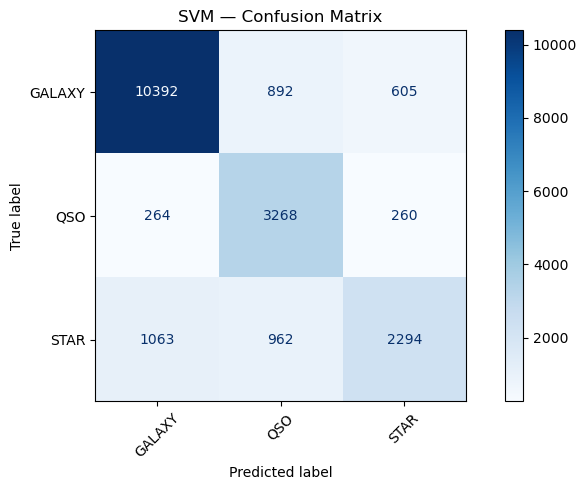

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['GALAXY','QSO','STAR']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['u','g','r','i','z']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be

In [19]:
evaluate_model("SVM")

## 14. Model 4 — Gradient Boosting

  File "c:\Users\aarya\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\aarya\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\aarya\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\aarya\anaconda3\Lib\subprocess.

              precision    recall  f1-score   support

      GALAXY       0.90      0.94      0.92     11889
         QSO       0.81      0.80      0.80      3792
        STAR       0.81      0.72      0.76      4319

    accuracy                           0.87     20000
   macro avg       0.84      0.82      0.83     20000
weighted avg       0.86      0.87      0.86     20000



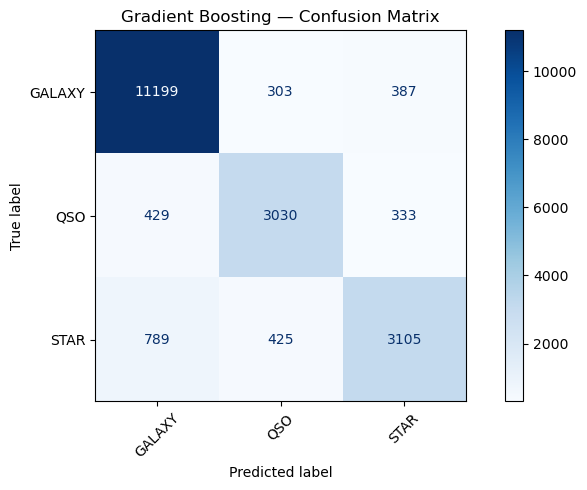

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['GALAXY','QSO','STAR']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['u','g','r','i','z']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be

In [20]:
evaluate_model("Gradient Boosting")

## 15. Compare all models

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Training Time (seconds)
0,Random Forest,0.8752,0.8501,0.8303,0.8393,0.8735,5.3907
1,Gradient Boosting,0.8667,0.8400,0.8200,0.8289,0.8646,2.7194
2,Decision Tree,0.8149,0.7706,0.7702,0.7704,0.8149,0.7713
3,SVM,0.7977,0.7503,0.7557,0.7424,0.7949,121.2987


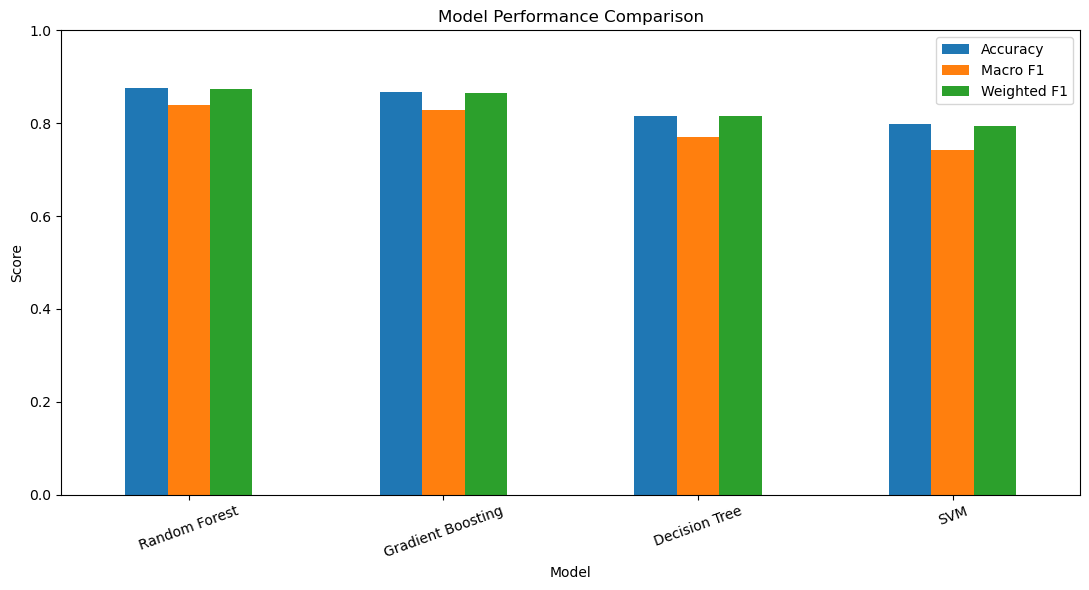

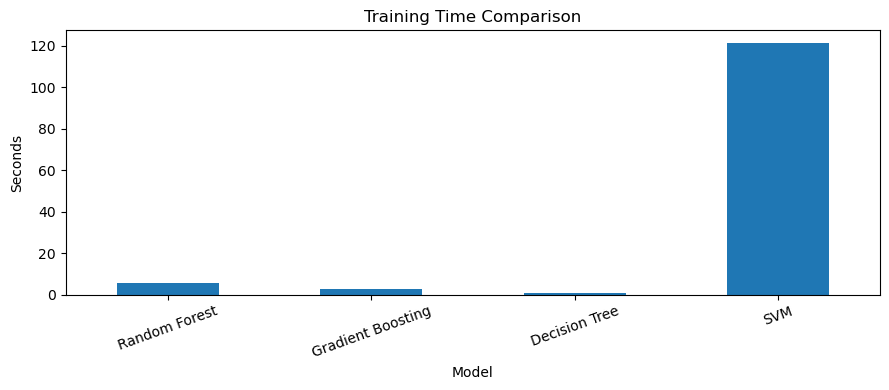

In [21]:
results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False).reset_index(drop=True)
display(results_df.round(4))
results_df.set_index("Model")[["Accuracy", "Macro F1", "Weighted F1"]].plot(
    kind="bar", figsize=(11, 6)
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
results_df.set_index("Model")["Training Time (seconds)"].plot(kind="bar", figsize=(9, 4))
plt.title("Training Time Comparison")
plt.ylabel("Seconds")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 16. Save models and best model

In [22]:
os.makedirs("saved_models", exist_ok=True)
for name, pipeline in trained_models.items():
    joblib.dump(pipeline, "saved_models/" + name.lower().replace(" ", "_") + ".joblib")

best_name = results_df.iloc[0]["Model"]  # best by Macro F1
best_model = trained_models[best_name]
joblib.dump(best_model, "saved_models/best_star_classifier.joblib")

metadata = {
    "best_model": best_name,
    "features": FEATURES,
    "target": TARGET,
    "classes": sorted(y.unique()),
    "selection_metric": "Macro F1",
    "test_metrics": results_df.iloc[0].to_dict()
}
with open("saved_models/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=float)
print("Best model:", best_name)
print("Saved models to saved_models/")

Best model: Random Forest
Saved models to saved_models/


## 17. Predict a new sample

In [23]:
# Example values are placeholders for demonstrating prediction.
new_sample = pd.DataFrame([{
    "u": 22.3, "g": 21.8, "r": 21.2, "i": 20.9, "z": 20.7
}])[FEATURES]
print("Predicted class:", best_model.predict(new_sample)[0])
if hasattr(best_model, "predict_proba"):
    probs = best_model.predict_proba(new_sample)[0]
    print(dict(zip(best_model.classes_, probs.round(4))))

Predicted class: QSO
{'GALAXY': np.float64(0.39), 'QSO': np.float64(0.485), 'STAR': np.float64(0.125)}


## Notes
- Exact metrics are only known after running this notebook on your CSV.
- The commonly used SDSS dataset may have no missing values. The notebook checks your exact file and median-imputes missing input values if present.
- We inspect outliers but do not delete them automatically.
- `class` is the target, never an input. IDs and survey metadata are not used in the initial model.
- The frontend expects `u`, `g`, `r`, `i`, `z`, and `redshift`. Use measured values from a catalogue for meaningful predictions.

In [24]:
import sklearn
print(sklearn.__version__)

1.9.0


In [25]:
import pandas as pd

for name, value in globals().copy().items():
    if isinstance(value, pd.DataFrame):
        print(f"\nVariable: {name}")
        print("Columns:", list(value.columns))
        print(value.head(2))


Variable: df
Columns: ['obj_ID', 'alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'run_ID', 'rerun_ID', 'cam_col', 'field_ID', 'spec_obj_ID', 'class', 'redshift', 'plate', 'MJD', 'fiber_ID']
         obj_ID       alpha      delta         u         g         r  \
0  1.237661e+18  135.689107  32.494632  23.87882  22.27530  20.39501   
1  1.237665e+18  144.826101  31.274185  24.77759  22.83188  22.58444   

          i         z  run_ID  rerun_ID  cam_col  field_ID   spec_obj_ID  \
0  19.16573  18.79371    3606       301        2        79  6.543777e+18   
1  21.16812  21.61427    4518       301        5       119  1.176014e+19   

    class  redshift  plate    MJD  fiber_ID  
0  GALAXY  0.634794   5812  56354       171  
1  GALAXY  0.779136  10445  58158       427  

Variable: data
Columns: ['u', 'g', 'r', 'i', 'z', 'class']
          u         g         r         i         z   class
0  23.87882  22.27530  20.39501  19.16573  18.79371  GALAXY
1  24.77759  22.83188  22.58444  21.16812  21.6142

In [26]:
from pathlib import Path

save_path = Path("saved_models/model_comparison.json")
save_path.parent.mkdir(parents=True, exist_ok=True)

results_df.to_json(
    save_path,
    orient="records",
    indent=2
)

print("File created:", save_path.resolve())
print("Exists:", save_path.exists())

File created: D:\ML_FINAL_FINAL\star_classification_project\saved_models\model_comparison.json
Exists: True


In [27]:
import joblib

model = joblib.load("saved_models/best_star_classifier.joblib")

joblib.dump(
    model,
    "saved_models/best_star_classifier_compressed.joblib",
    compress=3
)

['saved_models/best_star_classifier_compressed.joblib']

In [28]:
import numpy as np

original = joblib.load("saved_models/best_star_classifier.joblib")
compressed = joblib.load(
    "saved_models/best_star_classifier_compressed.joblib"
)

pred_original = original.predict(X_test)
pred_compressed = compressed.predict(X_test)

print("Identical predictions:",
      np.array_equal(pred_original, pred_compressed))

Identical predictions: True


In [29]:
import joblib
import os

path = "saved_models/random_forest.joblib"

model = joblib.load(path)

compressed_path = "saved_models/random_forest_compressed.joblib"

joblib.dump(model, compressed_path, compress=3)

print("Original size:",
      round(os.path.getsize(path) / (1024 * 1024), 2), "MB")

print("Compressed size:",
      round(os.path.getsize(compressed_path) / (1024 * 1024), 2), "MB")

Original size: 297.68 MB
Compressed size: 77.51 MB


In [30]:
compressed_model = joblib.load(compressed_path)

print(
    "Same predictions:",
    (model.predict(X_test) == compressed_model.predict(X_test)).all()
)

Same predictions: True
